# 1. Cleaning, and what gets thrown away

*Part of the [broadlisten](https://github.com/InteractionDataLab/broad-listening/tree/main/code)
stage-by-stage examples. Every number and figure below was produced by running
this notebook on the synthetic corpus in `broadlisten.sample`, which is
generated from templates and contains no participant data.*

Cleaning decides which responses reach every later stage, so its mistakes are
invisible afterwards: a filter that quietly drops short answers produces a
corpus where nobody was ever brief.

This stage is script-agnostic and its junk filter is built so that a three-word
answer is not mistaken for an empty one.

In [1]:
from broadlisten.sample import sample_corpus, THEMES

corpus = sample_corpus(seed=0)
print(f"{len(corpus)} responses, {len(THEMES)} planted themes")
print(f"columns: {list(corpus.columns)}")
corpus.head(4)

600 responses, 5 planted themes
columns: ['Participant', 'Team', 'question', 'text', 'planted_theme', 'n_words']


,Participant,Team,question,text,planted_theme,n_words
0,P0000,TEAM-11,Connection,"Looking back, I felt part of something",Belonging and support,7
1,P0000,TEAM-11,Team Work,we needed one place to write things down,Communication difficulty,8
2,P0000,TEAM-11,Beyond the project,"To be fair, the group was welcoming from the f...",Belonging and support,11
3,P0000,TEAM-11,Conditions,meetings,Communication difficulty,1


## What `minimal_clean` does

Lowercasing, contraction expansion and whitespace normalisation, with the
original kept alongside. The cleaned text is what gets embedded; the original is
what gets quoted, because a quotation has to be what the person actually
wrote.

In [2]:
from broadlisten.clean import minimal_clean

for raw in ["It's been a ROLLERCOASTER!!!   ",
            "We didn't have enough time,   but we managed",
            "L'equipe etait formidable"]:
    print(f"{raw!r}\n  -> {minimal_clean(raw)!r}")

"It's been a ROLLERCOASTER!!!   "
  -> 'it s been a rollercoaster'
"We didn't have enough time,   but we managed"
  -> 'we didn t have enough time but we managed'
"L'equipe etait formidable"
  -> 'l equipe etait formidable'


## The junk filter, and why it is not a length rule

A length threshold would reject "Funding." and keep "asdkjhasdkjh". These three
measures separate a short real answer from noise: the share of characters that
are letters, the number of word-like tokens, and the vowel density.

In [3]:
from broadlisten.clean import (DEFAULT_OUTLIER_RULE, alpha_ratio,
                               alpha_token_count, vowel_ratio)

samples = ["Funding.", "asdkjhasdkjh", "n/a", "...", "3", "we lacked time",
           "AAAAAAAAAA", "  "]
print(f"{'text':22s} {'alpha':>6} {'tokens':>7} {'vowel':>6}  usable")
for s in samples:
    print(f"{s!r:22s} {alpha_ratio(s):6.2f} {alpha_token_count(s):7d} "
          f"{vowel_ratio(s):6.2f}  {DEFAULT_OUTLIER_RULE.is_valid(s)}")

text                    alpha  tokens  vowel  usable
'Funding.'               0.88       1   0.29  True
'asdkjhasdkjh'           1.00       1   0.17  True
'n/a'                    0.67       1   0.50  True
'...'                    0.00       0   0.00  False
'3'                      0.00       0   0.00  False
'we lacked time'         0.86       3   0.42  True
'AAAAAAAAAA'             1.00       1   1.00  True
'  '                     0.00       0   0.00  False


## What that costs on the whole corpus

The share rejected is a number to report, not a detail. It is part of every
denominator downstream.

In [4]:
from IPython.display import Image

def png(fig, w=900, h=480):
    """Render a figure as a static PNG.

    GitHub's notebook viewer does not run Plotly, so an interactive figure is a
    blank cell to anyone reading this on the web. A PNG is visible to everyone.
    """
    return Image(fig.to_image(format="png", width=w, height=h, scale=2))

kept 542, rejected 58 of 600


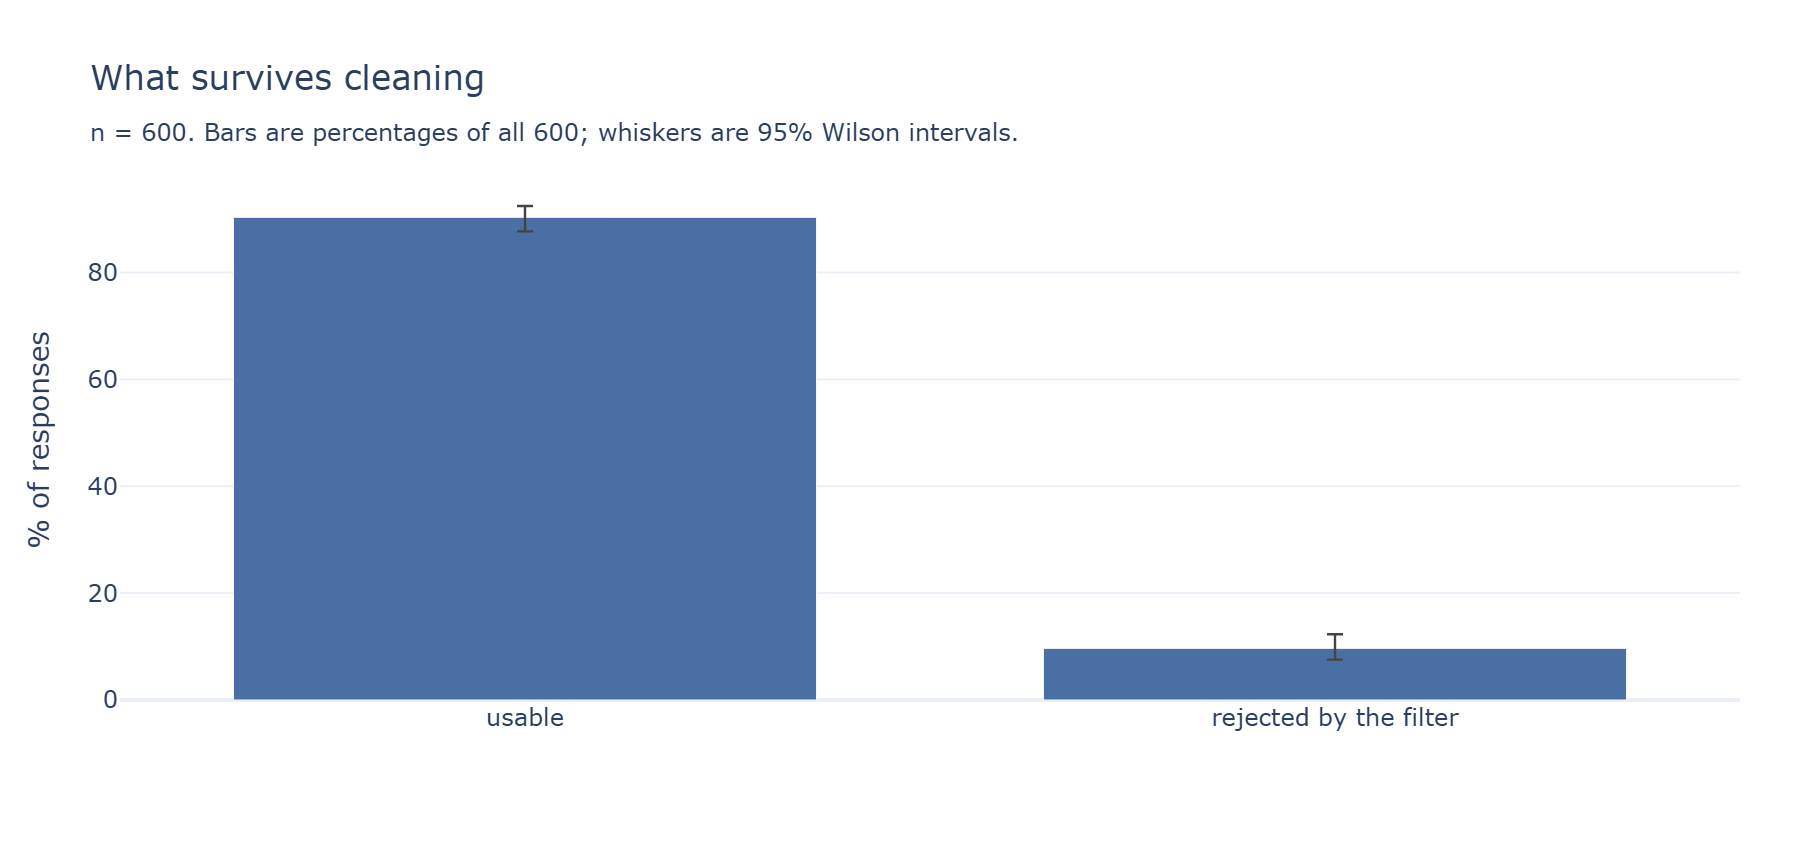

In [5]:
from broadlisten.explore import category_bars

corpus["usable"] = corpus.text.astype(str).map(DEFAULT_OUTLIER_RULE.is_valid)
counts = corpus.usable.value_counts()
kept, dropped = int(counts.get(True, 0)), int(counts.get(False, 0))
print(f"kept {kept}, rejected {dropped} of {len(corpus)}")

png(category_bars({"usable": kept, "rejected by the filter": dropped},
                  order=["usable", "rejected by the filter"],
                  title="What survives cleaning"), h=430)

**Next:** [2. Embedding](02_embed.ipynb) turns the surviving text into
vectors.